# N2-AT2 — Inteligência Artificial I
## Previsão de preços de diamantes: Regressão Linear × Random Forest

**Modalidade:** Aprendizado de Máquina Supervisionado (regressão)
**Base de dados:** *Diamonds* (53.940 registros, 10 atributos) — disponível em `seaborn-data`
**Algoritmos comparados:** Regressão Linear e Random Forest Regressor
**Grupo:** _(preencher com os nomes dos integrantes)_

> Como executar no Google Colab: faça upload do arquivo `diamonds.csv` (ou deixe o notebook baixar a base automaticamente da fonte original) e execute **Ambiente de execução → Executar tudo**.

---
## 1. Definição do problema

O preço de um diamante depende de um conjunto de características (as chamadas *4Cs*: **C**arat/peso, **C**ut/lapidação, **C**olor/cor e **C**larity/pureza) e de medidas físicas (dimensões e proporções). Avaliadores humanos precisam combinar essas informações de forma subjetiva, o que gera inconsistência de preços entre vendedores.

**Objetivo:** construir modelos que *prevejam o preço (em US$) a partir das características físicas e de qualidade da pedra*, e comparar dois algoritmos de naturezas diferentes:

| Algoritmo | Natureza |
|---|---|
| Regressão Linear | modelo paramétrico, linear, altamente interpretável |
| Random Forest | *ensemble* de árvores, não paramétrico, captura não linearidades e interações |

**Contribuição do Aprendizado de Máquina:** a relação entre peso (quilates) e preço é fortemente **não linear** (o preço cresce de forma acelerada com o tamanho) e há interações entre os atributos. Ver até que ponto um modelo simples (linear) consegue capturar esse comportamento, em comparação com um modelo flexível, é exatamente o tipo de análise que o problema pede.

## 2. Bibliotecas e configuração

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, KFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

os.makedirs("figuras", exist_ok=True)   # figuras usadas no relatório
RESULTADOS = {}                           # métricas salvas ao final (resultados.json)

def salvar_fig(nome):
    plt.tight_layout()
    plt.savefig(f"figuras/{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 3. Base de dados

Fonte: *Diamonds dataset* (originalmente do pacote `ggplot2`, R), distribuído em `seaborn-data`. Cada linha é um diamante.

| Atributo | Tipo | Descrição |
|---|---|---|
| `carat` | numérico | peso em quilates |
| `cut` | categórico ordinal | qualidade da lapidação (Fair < Good < Very Good < Premium < Ideal) |
| `color` | categórico ordinal | cor, de J (pior) a D (melhor) |
| `clarity` | categórico ordinal | pureza (I1 < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF) |
| `depth` | numérico | profundidade total (%) = z / média(x, y) |
| `table` | numérico | largura do topo em relação ao ponto mais largo (%) |
| `x`, `y`, `z` | numérico | comprimento, largura e profundidade (mm) |
| **`price`** | numérico | **variável-alvo**: preço em US$ |

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
try:
    df = pd.read_csv("diamonds.csv")          # arquivo entregue junto com o projeto
except FileNotFoundError:
    df = pd.read_csv(URL)                     # fonte original
    df.to_csv("diamonds.csv", index=False)

print(f"Registros: {df.shape[0]:,} | Atributos: {df.shape[1]}".replace(",", "."))
df.head()

Registros: 53.940 | Atributos: 10


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## 4. Análise exploratória
### 4.1 Estrutura e estatísticas descritivas

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.1 MB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.80,0.47,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.75,1.43,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.46,2.23,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.80,3989.44,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.73,1.12,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.73,1.14,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.54,0.71,0.0,2.91,3.53,4.04,31.80


In [5]:
n_ausentes   = int(df.isna().sum().sum())
n_duplicados = int(df.duplicated().sum())
n_zeros      = int((df[["x", "y", "z"]] == 0).any(axis=1).sum())
print("Valores ausentes:", n_ausentes)
print("Linhas duplicadas:", n_duplicados)
print("Linhas com alguma dimensão (x, y ou z) igual a zero:", n_zeros)
print("\nMaiores valores de y e z (mm):")
print(df[["y", "z"]].apply(lambda s: s.nlargest(3).values).T)

RESULTADOS["base"] = dict(n_registros=int(len(df)), n_atributos=int(df.shape[1]),
                          ausentes=n_ausentes, duplicados=n_duplicados, dimensao_zero=n_zeros)

Valores ausentes: 0
Linhas duplicadas: 146
Linhas com alguma dimensão (x, y ou z) igual a zero: 20

Maiores valores de y e z (mm):
      0      1      2
y  58.9  31.80  10.54
z  31.8   8.06   6.98


**Observações:** não há valores ausentes, mas existem **linhas duplicadas**, **diamantes com dimensão igual a zero** (fisicamente impossível, indica erro de registro) e **valores extremos incoerentes** em `y` e `z` (por exemplo, 58,9 mm e 31,8 mm para pedras de poucos quilates). Esses problemas serão tratados no pré-processamento.

### 4.2 Distribuição da variável-alvo e do peso

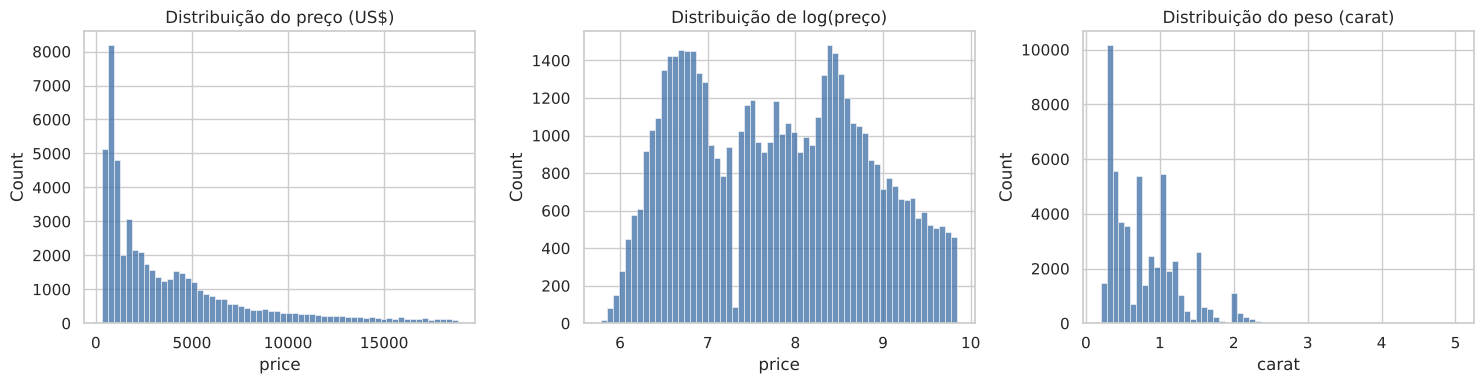

Assimetria do preço: 1.62 | de log(preço): 0.12


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["price"], bins=60, ax=ax[0], color="#3b6ea5")
ax[0].set_title("Distribuição do preço (US$)")
sns.histplot(np.log(df["price"]), bins=60, ax=ax[1], color="#3b6ea5")
ax[1].set_title("Distribuição de log(preço)")
sns.histplot(df["carat"], bins=60, ax=ax[2], color="#3b6ea5")
ax[2].set_title("Distribuição do peso (carat)")
salvar_fig("eda_distribuicoes")

print(f"Assimetria do preço: {df['price'].skew():.2f} | de log(preço): {np.log(df['price']).skew():.2f}")
RESULTADOS["base"]["assimetria_preco"] = float(df["price"].skew())
RESULTADOS["base"]["assimetria_log_preco"] = float(np.log(df["price"]).skew())

O preço é **fortemente assimétrico à direita**: muitos diamantes baratos e poucos muito caros. Isso importa para a escolha do modelo e das métricas, pois erros em pedras caras tendem a dominar o RMSE.

### 4.3 Relação entre preço e atributos

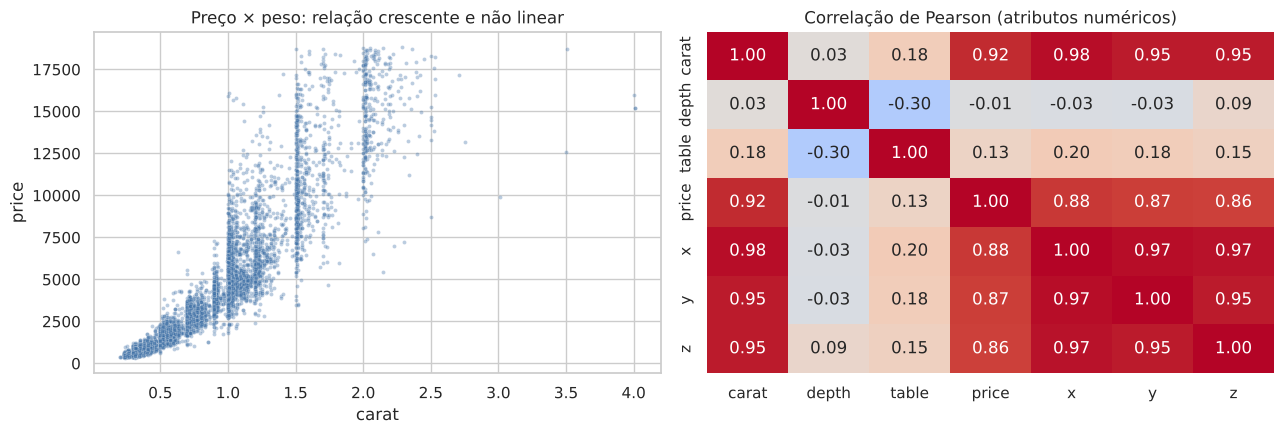

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
amostra = df.sample(8000, random_state=SEED)
sns.scatterplot(data=amostra, x="carat", y="price", s=8, alpha=0.35, ax=ax[0], color="#3b6ea5")
ax[0].set_title("Preço × peso: relação crescente e não linear")
corr = df.select_dtypes("number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1], cbar=False)
ax[1].set_title("Correlação de Pearson (atributos numéricos)")
salvar_fig("eda_carat_corr")

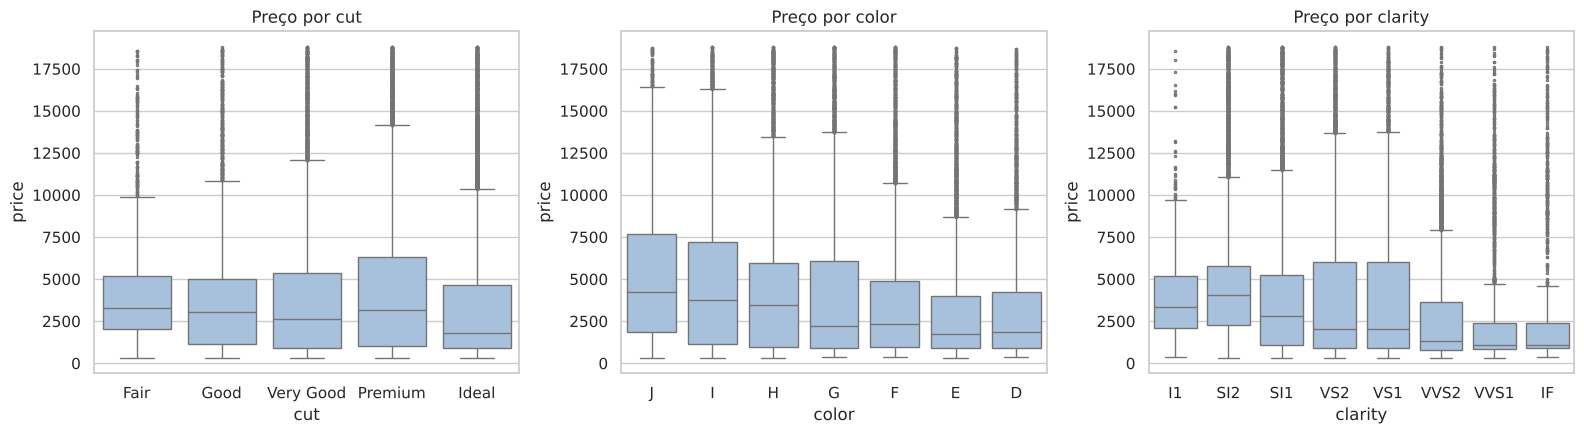

             price  carat
cut                      
Fair       4358.76   1.05
Good       3928.86   0.85
Very Good  3981.76   0.81
Premium    4584.26   0.89
Ideal      3457.54   0.70


In [8]:
ordem_cut     = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
ordem_color   = ["J", "I", "H", "G", "F", "E", "D"]
ordem_clarity = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (col, ordem) in zip(ax, [("cut", ordem_cut), ("color", ordem_color), ("clarity", ordem_clarity)]):
    sns.boxplot(data=df, x=col, y="price", order=ordem, ax=a, color="#9ec1e6", fliersize=1.5)
    a.set_title(f"Preço por {col}")
salvar_fig("eda_categoricas")

print(df.groupby("cut")[["price", "carat"]].mean().loc[ordem_cut].round(2))

**Principais padrões:**
- `carat` tem a maior correlação com o preço (≈ 0,92); `x`, `y` e `z` também são altamente correlacionadas com ele (≈ 0,86–0,88), mas são **fortemente correlacionadas entre si e com `carat`** (0,95–0,98): há **multicolinearidade**, o que afeta a interpretação dos coeficientes da regressão linear.
- A relação preço × peso é **convexa** (curva): um modelo linear tende a errar nas extremidades.
- Contraintuitivamente, a lapidação "Ideal" (a melhor) tem o **menor** preço médio entre as lapidações, e a cor "J" (a pior) tem o **maior** preço médio entre as cores. Isso ocorre porque pedras maiores (mais caras) tendem a ter cor e lapidação inferiores (peso médio de 1,16 ct na cor J contra 0,66 ct nas cores D/E): o peso é um fator de confusão. Um modelo multivariado precisa separar esses efeitos.

## 5. Pré-processamento

Etapas aplicadas:
1. **Remoção de duplicatas.**
2. **Remoção de inconsistências:** diamantes com `x`, `y` ou `z` iguais a zero e com dimensões fisicamente implausíveis (`y` > 20 mm ou `z` > 10 mm).
3. **Codificação das variáveis categóricas** como inteiros **ordinais**, respeitando a ordem natural de qualidade (faz sentido porque `cut`, `color` e `clarity` possuem hierarquia).
4. **Padronização** (`StandardScaler`) dos atributos, aplicada dentro de um `Pipeline` para evitar vazamento de dados (*data leakage*).
5. **Separação treino/teste** (80% / 20%) com semente fixa, igual para os dois algoritmos.

Não há valores ausentes a imputar. Os valores altos de preço **não** foram removidos: são diamantes legítimos e fazem parte do problema.

In [9]:
n0 = len(df)
dfc = df.drop_duplicates().copy()
n_apos_dup = len(dfc)

mask_zero = (dfc[["x", "y", "z"]] == 0).any(axis=1)
mask_extremo = (dfc["y"] > 20) | (dfc["z"] > 10)
dfc = dfc[~(mask_zero | mask_extremo)].copy()

print(f"Registros originais:               {n0:,}".replace(",", "."))
print(f"Removidos (duplicatas):            {n0 - n_apos_dup:,}".replace(",", "."))
print(f"Removidos (dimensões inválidas):   {n_apos_dup - len(dfc):,}".replace(",", "."))
print(f"Registros após a limpeza:          {len(dfc):,}".replace(",", "."))

# codificação ordinal
dfc["cut"]     = pd.Categorical(dfc["cut"],     categories=ordem_cut,     ordered=True).codes
dfc["color"]   = pd.Categorical(dfc["color"],   categories=ordem_color,   ordered=True).codes
dfc["clarity"] = pd.Categorical(dfc["clarity"], categories=ordem_clarity, ordered=True).codes

RESULTADOS["preprocessamento"] = dict(
    removidos_duplicatas=int(n0 - n_apos_dup),
    removidos_invalidos=int(n_apos_dup - len(dfc)),
    registros_finais=int(len(dfc)))

dfc.head()

Registros originais:               53.940
Removidos (duplicatas):            146
Removidos (dimensões inválidas):   22
Registros após a limpeza:          53.772


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4,5,1,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3,5,2,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1,5,4,56.9,65.0,327,4.05,4.07,2.31
3,0.29,3,1,3,62.4,58.0,334,4.20,4.23,2.63
4,0.31,1,0,1,63.3,58.0,335,4.34,4.35,2.75


In [10]:
FEATURES = ["carat", "cut", "color", "clarity", "depth", "table", "x", "y", "z"]
X = dfc[FEATURES]
y = dfc["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
print(f"Treino: {len(X_train):,} registros | Teste: {len(X_test):,} registros".replace(",", "."))
RESULTADOS["preprocessamento"].update(n_treino=int(len(X_train)), n_teste=int(len(X_test)))

# distribuições de treino e teste são semelhantes?
print(y_train.describe().round(1).to_frame("treino").join(y_test.describe().round(1).to_frame("teste")))

Treino: 43.017 registros | Teste: 10.755 registros
        treino    teste
count  43017.0  10755.0
mean    3938.5   3901.7
std     3996.9   3941.4
min      326.0    335.0
25%      954.0    942.0
50%     2400.0   2425.0
75%     5342.0   5277.5
max    18823.0  18736.0


## 6. Algoritmos selecionados

### 6.1 Regressão Linear
Modela `preço = β₀ + β₁·carat + β₂·cut + ... `, estimando os coeficientes por mínimos quadrados.
**Por que foi escolhida:** é o *baseline* clássico para regressão: rápida, determinística e interpretável. Serve para medir o quanto de relação linear existe nos dados e quanto é perdido quando a relação real é não linear.

### 6.2 Random Forest Regressor
Conjunto de árvores de decisão treinadas em amostras *bootstrap* e com sorteio de atributos em cada divisão; a previsão é a média das árvores.
**Por que foi escolhida:** captura não linearidades e interações entre atributos automaticamente, é robusta a *outliers* e a escalas diferentes e costuma ter bom desempenho em dados tabulares. Em contrapartida, é menos interpretável e mais custosa.

**Condições comparáveis:** mesma base limpa, mesmos atributos, **mesma divisão treino/teste**, mesmo pré-processamento (padronização em `Pipeline`) e **mesmas métricas**.

## 7. Metodologia: treinamento e avaliação

Para ambos os algoritmos:
1. **Validação cruzada com 5 *folds*** no conjunto de treino (estabilidade da estimativa);
2. **Treino final** no conjunto de treino completo e **avaliação no conjunto de teste**, nunca visto;
3. **Métricas:** MAE, MSE, RMSE e R². Também são medidos o desempenho no treino (para diagnóstico de *overfitting*), os tempos de treino/predição e o erro por faixa de preço;
4. **Melhorias de configuração** (uma por algoritmo): busca aleatória de hiperparâmetros para a Random Forest e transformação logarítmica do alvo para a Regressão Linear. São apresentadas separadamente do *baseline*.

In [11]:
def pipe(modelo):
    return Pipeline([("scaler", StandardScaler()), ("modelo", modelo)])

def metricas(y_real, y_prev):
    mse = mean_squared_error(y_real, y_prev)
    return dict(MAE=float(mean_absolute_error(y_real, y_prev)), MSE=float(mse),
                RMSE=float(np.sqrt(mse)), R2=float(r2_score(y_real, y_prev)))

modelos = {
    "Regressão Linear":       pipe(LinearRegression()),
    "Random Forest (base)":   pipe(RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)),
}

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

cv_res = {}
for nome, m in modelos.items():
    cv = cross_validate(m, X_train, y_train, cv=kf, scoring=scoring, n_jobs=1)
    cv_res[nome] = {k: (float(np.mean(-cv[f"test_{k}"] if k != "R2" else cv[f"test_{k}"])),
                        float(np.std(cv[f"test_{k}"]))) for k in scoring}

tab_cv = pd.DataFrame({n: {f"{k} (média)": v[k][0] for k in v} | {f"{k} (desvio)": v[k][1] for k in v}
                       for n, v in cv_res.items()}).T
RESULTADOS["cv"] = cv_res
print("Validação cruzada (5 folds) no conjunto de treino")
tab_cv.round(3)

Validação cruzada (5 folds) no conjunto de treino


,MAE (média),RMSE (média),R2 (média),MAE (desvio),RMSE (desvio),R2 (desvio)
Regressão Linear,801.060,1207.564,0.909,5.119,23.911,0.003
Random Forest (base),271.929,551.452,0.981,4.486,14.480,0.001


## 8. Treinamento e resultados

In [12]:
preds_teste, preds_treino, tempos = {}, {}, {}
res = {}

def treinar_e_avaliar(nome, modelo):
    t0 = time.time(); modelo.fit(X_train, y_train); t_fit = time.time() - t0
    t0 = time.time(); p_te = modelo.predict(X_test); t_pred = time.time() - t0
    p_tr = modelo.predict(X_train)
    preds_teste[nome], preds_treino[nome] = p_te, p_tr
    res[nome] = dict(teste=metricas(y_test, p_te), treino=metricas(y_train, p_tr),
                     tempo_treino_s=float(t_fit), tempo_predicao_s=float(t_pred))

for nome, m in modelos.items():
    treinar_e_avaliar(nome, m)

def tabela_resultados(nomes):
    linhas = []
    for n in nomes:
        r = res[n]
        linhas.append({"Modelo": n,
                       "MAE (teste)": r["teste"]["MAE"], "RMSE (teste)": r["teste"]["RMSE"],
                       "MSE (teste)": r["teste"]["MSE"], "R² (teste)": r["teste"]["R2"],
                       "R² (treino)": r["treino"]["R2"],
                       "Tempo treino (s)": r["tempo_treino_s"]})
    return pd.DataFrame(linhas).set_index("Modelo")

tabela_resultados(list(modelos)).round(3)

,MAE (teste),RMSE (teste),MSE (teste),R² (teste),R² (treino),Tempo treino (s)
Modelo,,,,,,
Regressão Linear,797.908,1215.800,1478169.729,0.905,0.909,0.013
Random Forest (base),264.682,524.777,275390.421,0.982,0.997,7.549


### 8.1 Melhorias de configuração
**Random Forest:** busca aleatória (`RandomizedSearchCV`, 3 *folds*) sobre número de árvores, profundidade máxima, tamanho mínimo de folha e atributos por divisão.
**Regressão Linear:** como o preço é assimétrico e a relação com o peso é curva, ajusta-se a regressão sobre `log(preço)` e as previsões são convertidas de volta para dólares.

In [13]:
espaco = {
    "modelo__n_estimators": [100, 200, 300],
    "modelo__max_depth": [None, 20, 30],
    "modelo__min_samples_leaf": [1, 2, 4],
    "modelo__max_features": [1.0, 0.7, 0.5],
}
busca = RandomizedSearchCV(pipe(RandomForestRegressor(random_state=SEED, n_jobs=-1)),
                           espaco, n_iter=8, cv=3, scoring="neg_root_mean_squared_error",
                           random_state=SEED, n_jobs=1)
t0 = time.time(); busca.fit(X_train, y_train); t_busca = time.time() - t0
print("Melhores hiperparâmetros:", busca.best_params_)
print(f"Tempo da busca: {t_busca:.0f} s")

modelos["Random Forest (ajustado)"] = busca.best_estimator_
treinar_e_avaliar("Random Forest (ajustado)", busca.best_estimator_)   # reajusta no treino completo (mesmos parâmetros)

lr_log = TransformedTargetRegressor(regressor=pipe(LinearRegression()), func=np.log, inverse_func=np.exp)
modelos["Regressão Linear (alvo log)"] = lr_log
treinar_e_avaliar("Regressão Linear (alvo log)", lr_log)

RESULTADOS["melhores_hiperparametros"] = {k.replace("modelo__", ""): (None if v is None else float(v) if isinstance(v, float) else int(v))
                                          for k, v in busca.best_params_.items()}
RESULTADOS["tempo_busca_s"] = float(t_busca)

tabela_resultados(list(modelos)).round(3)

Melhores hiperparâmetros: {'modelo__n_estimators': 200, 'modelo__min_samples_leaf': 1, 'modelo__max_features': 0.7, 'modelo__max_depth': None}
Tempo da busca: 156 s


,MAE (teste),RMSE (teste),MSE (teste),R² (teste),R² (treino),Tempo treino (s)
Modelo,,,,,,
Regressão Linear,797.908,1215.800,1478169.729,0.905,0.909,0.013
Random Forest (base),264.682,524.777,275390.421,0.982,0.997,7.549
Random Forest (ajustado),263.000,519.491,269871.139,0.983,0.997,10.755
Regressão Linear (alvo log),457.794,876.757,768702.580,0.951,0.950,0.014


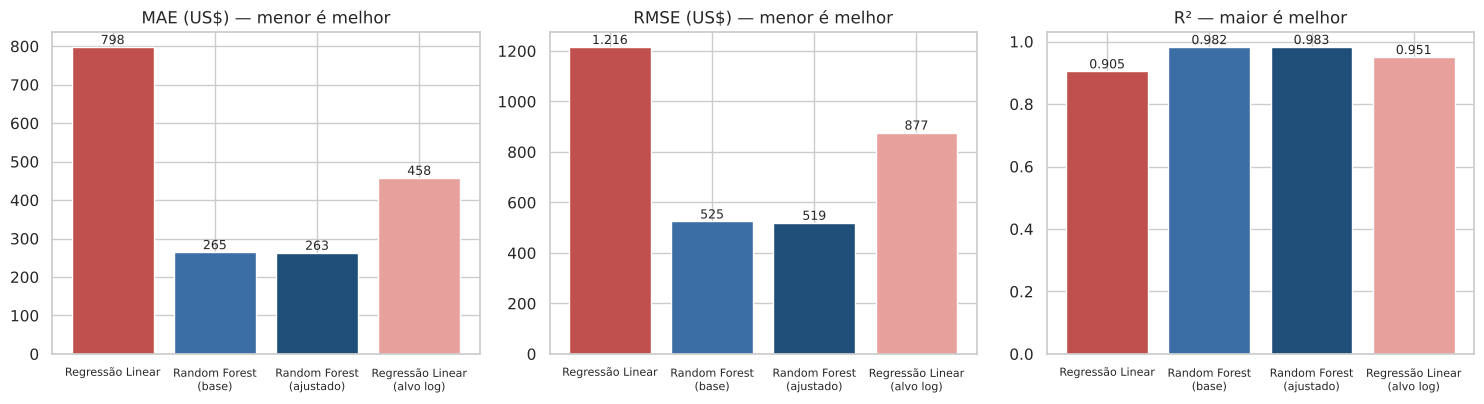

In [14]:
RESULTADOS["modelos"] = res

# ---- Gráfico comparativo de métricas (teste) ----
nomes = list(res)
cores = ["#c0504d", "#3b6ea5", "#1f4e79", "#e8a09d"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, met, tit in zip(ax, ["MAE", "RMSE", "R2"], ["MAE (US$) — menor é melhor", "RMSE (US$) — menor é melhor", "R² — maior é melhor"]):
    vals = [res[n]["teste"][met] for n in nomes]
    b = a.bar(range(len(nomes)), vals, color=cores)
    a.set_xticks(range(len(nomes))); a.set_xticklabels([n.replace(" (", "\n(") for n in nomes], fontsize=8)
    a.set_title(tit)
    for rect, v in zip(b, vals):
        a.text(rect.get_x() + rect.get_width()/2, v, f"{v:.3f}" if met == "R2" else f"{v:,.0f}".replace(",", "."),
               ha="center", va="bottom", fontsize=9)
salvar_fig("comparacao_metricas")

### 8.2 Previsto × real e análise dos resíduos

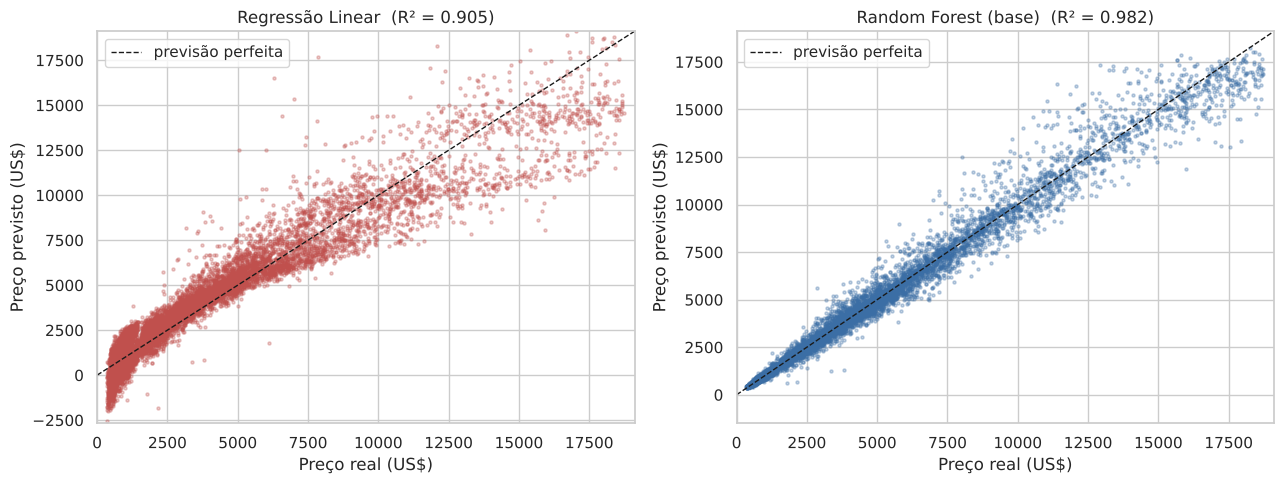

In [15]:
principais = ["Regressão Linear", "Random Forest (base)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
lim = [0, float(y_test.max()) * 1.02]
for a, n, c in zip(ax, principais, ["#c0504d", "#3b6ea5"]):
    a.scatter(y_test, preds_teste[n], s=5, alpha=0.3, color=c)
    a.plot(lim, lim, "k--", lw=1, label="previsão perfeita")
    a.set_xlim(lim); a.set_ylim(min(-1500, preds_teste[n].min() * 1.05), lim[1])
    a.set_xlabel("Preço real (US$)"); a.set_ylabel("Preço previsto (US$)")
    a.set_title(f"{n}  (R² = {res[n]['teste']['R2']:.3f})"); a.legend()
salvar_fig("previsto_vs_real")

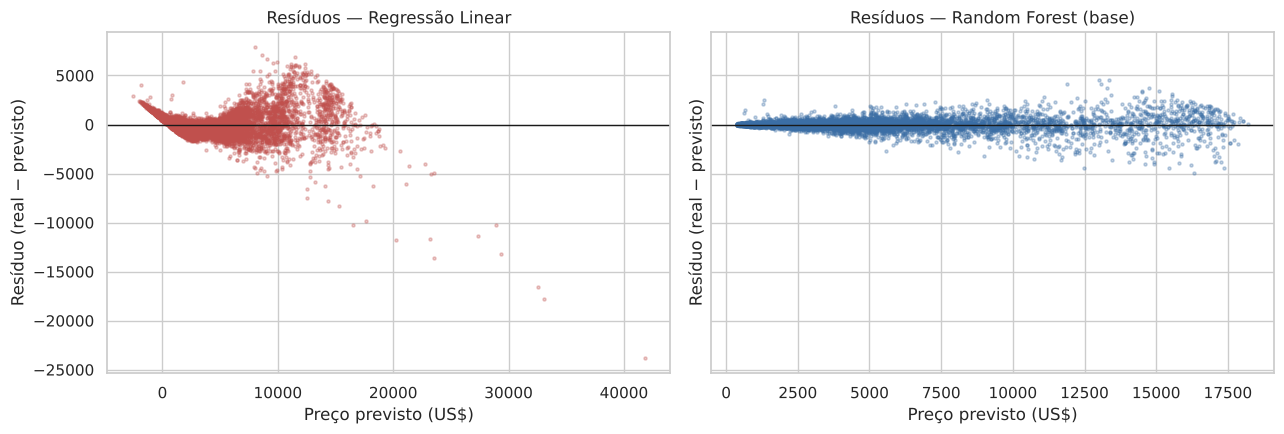

Previsões negativas da Regressão Linear no teste: 888 de 10755


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a, n, c in zip(ax, principais, ["#c0504d", "#3b6ea5"]):
    resid = y_test.values - preds_teste[n]
    a.scatter(preds_teste[n], resid, s=5, alpha=0.3, color=c)
    a.axhline(0, color="k", lw=1)
    a.set_xlabel("Preço previsto (US$)"); a.set_ylabel("Resíduo (real − previsto)")
    a.set_title(f"Resíduos — {n}")
salvar_fig("residuos")

neg = int((preds_teste["Regressão Linear"] < 0).sum())
print(f"Previsões negativas da Regressão Linear no teste: {neg} de {len(y_test)}")
RESULTADOS["previsoes_negativas_lr"] = neg

### 8.3 Comportamento por faixa de preço
Uma métrica global pode esconder diferenças relevantes. Abaixo, o erro é calculado separadamente para cada faixa de preço, em valor absoluto (MAE) e relativo (erro percentual médio absoluto, MAPE).

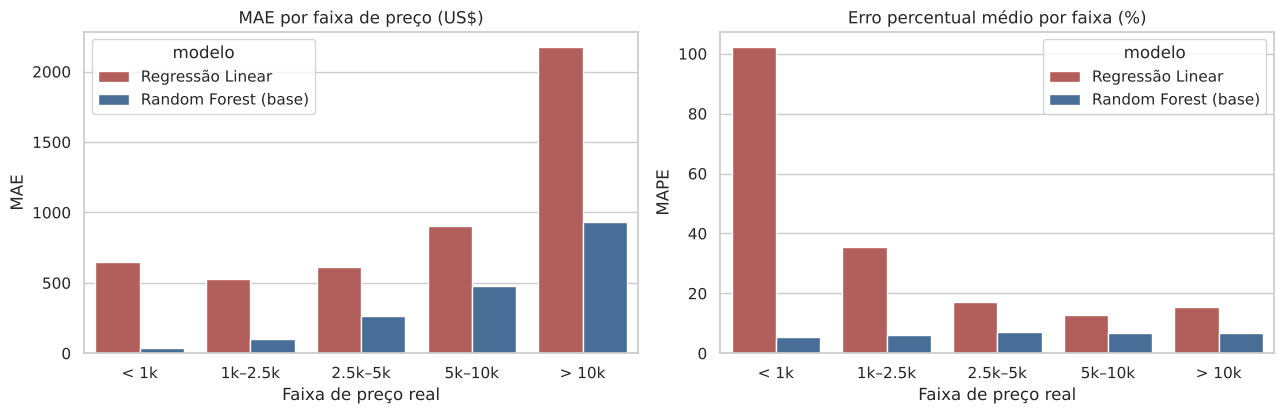

n                                   MAE  \
modelo  Random Forest (base) Regressão Linear Random Forest (base)   
faixa                                                                
< 1k                  2926.0           2926.0                 38.8   
1k–2.5k               2544.0           2544.0                102.8   
2.5k–5k               2384.0           2384.0                266.5   
5k–10k                1917.0           1917.0                478.9   
> 10k                  984.0            984.0                933.2   

                                         MAPE                   
modelo  Regressão Linear Random Forest (base) Regressão Linear  
faixa                                                           
< 1k               651.7                  5.6            102.2  
1k–2.5k            526.7                  6.1             35.4  
2.5k–5k            611.7                  7.3             17.1  
5k–10k             905.7                  6.9             12.9  
> 10k             2175.1                  6.9             15.5

In [17]:
faixas = [0, 1000, 2500, 5000, 10000, np.inf]
rotulos = ["< 1k", "1k–2.5k", "2.5k–5k", "5k–10k", "> 10k"]
cat = pd.cut(y_test, bins=faixas, labels=rotulos, right=False).values
yt = y_test.values

linhas = []
for n in ["Regressão Linear", "Random Forest (base)"]:
    for r in rotulos:
        m = cat == r
        linhas.append(dict(modelo=n, faixa=r, n=int(m.sum()),
                           MAE=float(mean_absolute_error(yt[m], preds_teste[n][m])),
                           MAPE=float(np.mean(np.abs(yt[m] - preds_teste[n][m]) / yt[m]) * 100)))
faixas_df = pd.DataFrame(linhas)
RESULTADOS["faixas"] = faixas_df.to_dict(orient="records")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
sns.barplot(data=faixas_df, x="faixa", y="MAE", hue="modelo", palette=["#c0504d", "#3b6ea5"], ax=ax[0])
ax[0].set_title("MAE por faixa de preço (US$)"); ax[0].set_xlabel("Faixa de preço real")
sns.barplot(data=faixas_df, x="faixa", y="MAPE", hue="modelo", palette=["#c0504d", "#3b6ea5"], ax=ax[1])
ax[1].set_title("Erro percentual médio por faixa (%)"); ax[1].set_xlabel("Faixa de preço real")
salvar_fig("erro_por_faixa")

faixas_df.pivot(index="faixa", columns="modelo", values=["n", "MAE", "MAPE"]).loc[rotulos].round(1)

### 8.4 Importância dos atributos

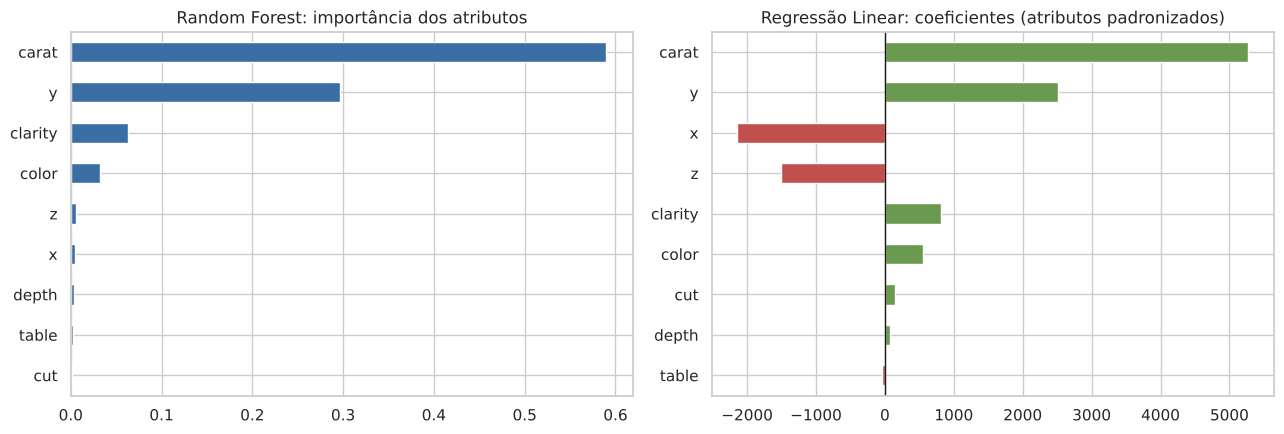

carat      0.5898
y          0.2969
clarity    0.0633
color      0.0327
z          0.0053
x          0.0048
depth      0.0030
table      0.0023
cut        0.0018


In [18]:
rf = modelos["Random Forest (base)"].named_steps["modelo"]
imp_rf = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
lr = modelos["Regressão Linear"].named_steps["modelo"]
coef_lr = pd.Series(lr.coef_, index=FEATURES)      # atributos padronizados -> coeficientes comparáveis
coef_lr = coef_lr.reindex(coef_lr.abs().sort_values().index)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
imp_rf.plot.barh(ax=ax[0], color="#3b6ea5"); ax[0].set_title("Random Forest: importância dos atributos")
coef_lr.plot.barh(ax=ax[1], color=["#c0504d" if v < 0 else "#6a9a4f" for v in coef_lr]); ax[1].axvline(0, color="k", lw=1)
ax[1].set_title("Regressão Linear: coeficientes (atributos padronizados)")
salvar_fig("importancia")

RESULTADOS["importancia_rf"] = {k: float(v) for k, v in imp_rf.sort_values(ascending=False).items()}
RESULTADOS["coef_lr"] = {k: float(v) for k, v in coef_lr.sort_values(key=abs, ascending=False).items()}
print(imp_rf.sort_values(ascending=False).round(4).to_string())

## 9. Análise comparativa

A tabela final consolida as duas abordagens principais sob as mesmas condições. A interpretação (diferenças, vantagens, limitações, comportamento em diferentes situações e melhorias) está na seção de conclusão abaixo e detalhada no relatório técnico em PDF.

In [19]:
final = tabela_resultados(list(res))
final["Tempo predição (s)"] = [res[n]["tempo_predicao_s"] for n in final.index]
final.round(3)

,MAE (teste),RMSE (teste),MSE (teste),R² (teste),R² (treino),Tempo treino (s),Tempo predição (s)
Modelo,,,,,,,
Regressão Linear,797.908,1215.800,1478169.729,0.905,0.909,0.013,0.002
Random Forest (base),264.682,524.777,275390.421,0.982,0.997,7.549,0.208
Random Forest (ajustado),263.000,519.491,269871.139,0.983,0.997,10.755,0.429
Regressão Linear (alvo log),457.794,876.757,768702.580,0.951,0.950,0.014,0.002


In [20]:
melhor = min(["Regressão Linear", "Random Forest (base)"], key=lambda n: res[n]["teste"]["RMSE"])
rf_, lr_ = res["Random Forest (base)"]["teste"], res["Regressão Linear"]["teste"]
print(f"Entre os dois algoritmos (baseline), o melhor no teste é: {melhor}")
print(f"  RMSE: Regressão Linear = US$ {lr_['RMSE']:.0f} | Random Forest = US$ {rf_['RMSE']:.0f}  "
      f"(redução de {100*(1-rf_['RMSE']/lr_['RMSE']):.1f}%)")
print(f"  MAE : Regressão Linear = US$ {lr_['MAE']:.0f} | Random Forest = US$ {rf_['MAE']:.0f}  "
      f"(redução de {100*(1-rf_['MAE']/lr_['MAE']):.1f}%)")
print(f"  R²  : Regressão Linear = {lr_['R2']:.3f} | Random Forest = {rf_['R2']:.3f}")

Entre os dois algoritmos (baseline), o melhor no teste é: Random Forest (base)
  RMSE: Regressão Linear = US$ 1216 | Random Forest = US$ 525  (redução de 56.8%)
  MAE : Regressão Linear = US$ 798 | Random Forest = US$ 265  (redução de 66.8%)
  R²  : Regressão Linear = 0.905 | Random Forest = 0.982


## 10. Demonstração prática

A função abaixo recebe as características de um diamante e devolve o preço previsto pelos dois algoritmos. Primeiro com diamantes fictícios; depois com amostras aleatórias do conjunto de teste, comparando com o preço real.

In [21]:
def prever_preco(carat, cut, color, clarity, depth, table, x, y, z):
    linha = pd.DataFrame([{
        "carat": carat, "cut": ordem_cut.index(cut), "color": ordem_color.index(color),
        "clarity": ordem_clarity.index(clarity), "depth": depth, "table": table, "x": x, "y": y, "z": z}])[FEATURES]
    return {"Regressão Linear": float(modelos["Regressão Linear"].predict(linha)[0]),
            "Random Forest (base)": float(modelos["Random Forest (base)"].predict(linha)[0]),
            "Random Forest (ajustado)": float(modelos["Random Forest (ajustado)"].predict(linha)[0])}

exemplos = {
    "Pequeno, qualidade média (0,30 ct, Good/H/SI1)":  (0.30, "Good",      "H", "SI1", 62.0, 58.0, 4.30, 4.32, 2.67),
    "Médio, alta qualidade (1,00 ct, Ideal/E/VS1)":     (1.00, "Ideal",     "E", "VS1", 61.8, 56.0, 6.45, 6.48, 4.00),
    "Grande, qualidade média (2,50 ct, Premium/I/SI2)": (2.50, "Premium",   "I", "SI2", 62.3, 59.0, 8.60, 8.55, 5.35),
    "Muito grande, topo (3,50 ct, Ideal/D/VVS1)":       (3.50, "Ideal",     "D", "VVS1", 61.5, 57.0, 9.60, 9.65, 5.92),
}
demo = pd.DataFrame({n: prever_preco(*v) for n, v in exemplos.items()}).T.round(0)
demo

,Regressão Linear,Random Forest (base),Random Forest (ajustado)
"Pequeno, qualidade média (0,30 ct, Good/H/SI1)",-1391.0,444.0,444.0
"Médio, alta qualidade (1,00 ct, Ideal/E/VS1)",6663.0,8634.0,8544.0
"Grande, qualidade média (2,50 ct, Premium/I/SI2)",18037.0,15920.0,15689.0
"Muito grande, topo (3,50 ct, Ideal/D/VVS1)",32759.0,17127.0,16825.0


In [22]:
amostra = X_test.sample(8, random_state=7)
demo2 = pd.DataFrame({
    "carat": amostra["carat"].values,
    "preço real": y_test.loc[amostra.index].values,
    "Reg. Linear": modelos["Regressão Linear"].predict(amostra),
    "Random Forest": modelos["Random Forest (base)"].predict(amostra),
}, index=range(1, 9))
demo2 = demo2.round({"preço real": 0, "Reg. Linear": 0, "Random Forest": 0})
demo2["erro RL"] = (demo2["Reg. Linear"] - demo2["preço real"]).round(0)
demo2["erro RF"] = (demo2["Random Forest"] - demo2["preço real"]).round(0)
demo2["carat"] = amostra["carat"].values   # mantém as casas decimais do peso
demo2

,carat,preço real,Reg. Linear,Random Forest,erro RL,erro RF
1,0.70,2415,2849.0,2376.0,434.0,-39.0
2,1.08,3302,3278.0,3413.0,-24.0,111.0
3,0.71,2549,3779.0,2525.0,1230.0,-24.0
4,0.41,1107,670.0,1090.0,-437.0,-17.0
5,0.42,1103,1370.0,1093.0,267.0,-10.0
6,0.72,2578,3083.0,2745.0,505.0,167.0
7,0.32,858,1940.0,921.0,1082.0,63.0
8,1.50,13135,10195.0,13413.0,-2940.0,278.0


## 11. Conclusão

### Resultados principais
No conjunto de teste (10.755 diamantes nunca vistos no treino), a **Random Forest** superou claramente a **Regressão Linear**:

| Métrica | Regressão Linear | Random Forest | Diferença |
|---|---|---|---|
| RMSE (US$) | 1.216 | 525 | −57% |
| MAE (US$) | 798 | 265 | −67% |
| R² | 0,905 | 0,982 | +0,077 |

A validação cruzada (5 *folds*) confirma o resultado: RMSE de 1.208 ± 24 para a Regressão Linear e 551 ± 14 para a Random Forest. A diferença entre os algoritmos é dezenas de vezes maior que a variação entre *folds*, portanto não é efeito do acaso na divisão dos dados.

### Diferenças, vantagens e limitações

**Regressão Linear**
- *Vantagens:* treino instantâneo (milissegundos), sem hiperparâmetros, resultado determinístico e coeficientes que podem ser lidos.
- *Limitações:* sofre de **subajuste** (R² de 0,909 no treino e 0,905 no teste: o modelo é simplesmente limitado demais, e não instável). Não captura a curva preço × peso, o que gerou **888 previsões negativas (8,3% do teste)** e erro percentual médio de 102% nas pedras abaixo de US$ 1.000. Na demonstração, previu preço negativo para uma pedra de 0,30 ct e US$ 32,7 mil para uma de 3,5 ct (acima do máximo da base, US$ 18.823). Com atributos muito correlacionados, os coeficientes ficam instáveis: `x` recebeu coeficiente **negativo**, apesar de pedras mais largas serem mais caras.

**Random Forest**
- *Vantagens:* captura não linearidades e interações sem que isso seja especificado; o erro percentual é **estável em todas as faixas de preço (5,6% a 7,3%)**; nunca prevê fora da faixa de preços vista no treino; lida bem com atributos correlacionados.
- *Limitações:* há alguma diferença entre treino (R² 0,997) e teste (R² 0,982), indicando ajuste excessivo moderado, ainda que com boa generalização; treino e predição são mais lentos (segundos contra milissegundos); é menos interpretável; e **não extrapola**: para o diamante de 3,5 ct, previu cerca de US$ 17 mil, preso ao teto dos dados de treino. Em valor absoluto, o erro cresce com o preço (MAE de US$ 933 na faixa acima de US$ 10 mil).

**Importância dos atributos (Random Forest):** `carat` (59%) e `y` (30%) concentram quase toda a importância; em seguida vêm `clarity` (6%) e `color` (3%). A lapidação (`cut`) contribui menos de 1% depois de se conhecer o tamanho. Como `carat`, `x`, `y` e `z` são redundantes entre si, a divisão da importância entre elas deve ser lida com cautela: o que o resultado mostra é que o **tamanho** da pedra domina o preço.

### Melhorias de configuração avaliadas
- **Random Forest ajustada** (busca aleatória de hiperparâmetros): RMSE de 519 contra 525 do *baseline* (−1%). O ganho é marginal, o que indica que a configuração padrão já está perto do limite do algoritmo com estes atributos.
- **Regressão Linear com alvo em log:** RMSE de 877 contra 1.216 (−28%) e R² de 0,951, sem custo computacional. É um ganho grande para uma mudança simples, mas o modelo ainda fica atrás da Random Forest.

### Abordagem mais adequada
Para prever o preço com a maior precisão possível, a **Random Forest** é a abordagem mais adequada: tem menos da metade do erro da Regressão Linear, comportamento consistente em todas as faixas de preço e nenhum resultado absurdo. Se a interpretabilidade for requisito, a Regressão Linear com alvo em log é um compromisso razoável, desde que se aceite um erro maior.

### Limitações do estudo e possíveis melhorias
- A base é um retrato de um mercado específico (preços em US$ sem correção, máximo de US$ 18.823); o modelo não deve ser usado para pedras maiores, de outras épocas, ou sem ajustar os preços.
- A avaliação usa uma única divisão treino/teste (apoiada por validação cruzada no treino); não foram calculados intervalos de confiança para as métricas de teste.
- Os atributos de qualidade foram codificados como ordinais (distâncias iguais entre níveis é uma hipótese simplificadora), e a base não traz informações como certificação ou fluorescência.
- **Melhorias possíveis:** criar atributos derivados (volume `x·y·z`, `log(carat)`, termos polinomiais para a Regressão Linear); testar modelos de *boosting* (Gradient Boosting, XGBoost, LightGBM); prever intervalos de preço em vez de um único valor; e usar validação cruzada repetida para quantificar a incerteza das métricas.

## 12. Referências
- Wickham, H. *ggplot2: Elegant Graphics for Data Analysis*. Springer, 2016. (origem do conjunto *diamonds*)
- Waskom, M. *seaborn-data*: repositório de conjuntos de dados. https://github.com/mwaskom/seaborn-data
- Pedregosa, F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830, 2011.
- Breiman, L. Random Forests. *Machine Learning*, 45(1), 5–32, 2001.
- Géron, A. *Mãos à Obra: Aprendizado de Máquina com Scikit-Learn, Keras & TensorFlow*. Alta Books.
- Documentação do scikit-learn: https://scikit-learn.org/stable/

In [23]:
with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(RESULTADOS, f, ensure_ascii=False, indent=2)
print("Resultados salvos em resultados.json")

Resultados salvos em resultados.json
